# 03 · Your first fit

**Level:** beginner · **Prerequisites:** [01](01_first_light_curve.ipynb) · **Run time:** ~1 min

**Covers:** simulating data, a likelihood, maximum likelihood with scipy, MCMC with emcee, reading the posterior

We simulate a TESS-like light curve of a hot Jupiter, find the best-fitting parameters, and measure their uncertainties with MCMC.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import emcee
import corner
import pizzetti

SMOKE = os.environ.get("PIZZETTI_SMOKE") == "1"

## 1. Simulated data

Seven transits at 2-minute cadence with 500 ppm white noise. We generate the data with pizzetti's
most accurate setting (quadrature at the limb, series off) and fit with the default, fast setting.

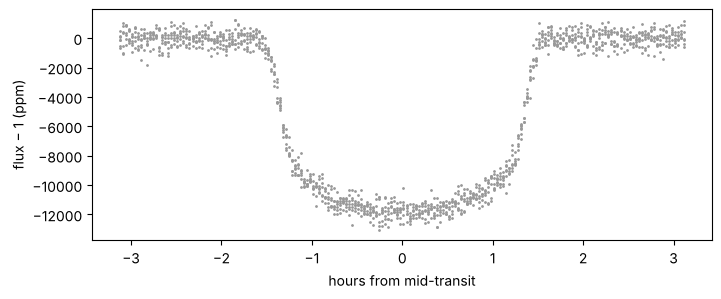

In [2]:
truth = dict(t0=0.0, per=3.5, rp=0.10, a=9.0, b=0.35, u1=0.40, u2=0.25)
sigma = 500e-6
t = (np.arange(7)[:, None] * truth["per"] + np.arange(-0.13, 0.13, 2.0 / 1440)[None, :]).ravel()

params = pizzetti.TransitParams()
params.ecc, params.w, params.limb_dark = 0.0, 90.0, "quadratic"

def set_params(th):
    t0, per, rp, a, b, u1, u2 = th
    params.t0, params.per, params.rp, params.a = t0, per, rp, a
    params.inc = np.degrees(np.arccos(b / a))
    params.u = [u1, u2]

th_true = np.array(list(truth.values()))
set_params(th_true)
y = pizzetti.TransitModel(params, t, series_tol=0.0, limb="quadrature").light_curve(params)
y = y + sigma * np.random.default_rng(42).standard_normal(t.size)

model = pizzetti.TransitModel(params, t)       # the model used in the fit
fold = (t + 0.5 * truth["per"]) % truth["per"] - 0.5 * truth["per"]
plt.figure(figsize=(8, 3)); plt.plot(24 * fold, 1e6 * (y - 1), ".", ms=2, color="0.6")
plt.xlabel("hours from mid-transit"); plt.ylabel("flux − 1 (ppm)");

## 2. The likelihood

With white Gaussian noise, the log-likelihood is −χ²/2. We sample the impact parameter `b` instead
of the inclination and require a physical intensity profile (positive and darkening towards the limb:
u₁ > 0, u₁ + u₂ < 1, u₁ + 2u₂ > 0).

In [3]:
names = ["t0", "per", "rp", "a", "b", "u1", "u2"]

def log_prob(th):
    t0, per, rp, a, b, u1, u2 = th
    if not (0 < rp < 0.5 and 1.5 < a < 100 and 0 <= b < 1 + rp and u1 > 0 and u1 + u2 < 1 and u1 + 2 * u2 > 0):
        return -np.inf
    set_params(th)
    r = y - model.light_curve(params)
    return -0.5 * np.dot(r, r) / sigma**2

print("log-likelihood at the truth:", log_prob(th_true))

log-likelihood at the truth: -649.3990173401158


## 3. Maximum likelihood

Start from a guess and minimise −log L. Scaling each parameter by a typical step makes the optimiser's
job easier.

In [4]:
scale = np.array([1e-4, 1e-6, 1e-3, 0.05, 0.02, 0.02, 0.02])
start = th_true + np.array([4e-4, 3e-6, 4e-3, -0.2, 0.08, 0.05, -0.05])
nll = lambda x: -log_prob(start + x * scale)
res = minimize(nll, np.zeros(7), method="Nelder-Mead", options=dict(maxfev=20000, xatol=1e-6, fatol=1e-6, adaptive=True))
best = start + res.x * scale
for n, v, tv in zip(names, best, th_true):
    print(f"{n:4s} best {v:12.6g}   truth {tv:10.6g}")

t0   best -0.000137669   truth          0
per  best      3.50005   truth        3.5
rp   best    0.0999051   truth        0.1
a    best      9.12704   truth          9
b    best     0.314956   truth       0.35
u1   best     0.440131   truth        0.4
u2   best     0.175227   truth       0.25


## 4. Uncertainties with MCMC

emcee explores the posterior with an ensemble of walkers started around the maximum.

In [5]:
nwalkers, nsteps = 32, (400 if SMOKE else 3000)
p0 = best + 0.1 * scale * np.random.default_rng(1).standard_normal((nwalkers, 7))
sampler = emcee.EnsembleSampler(nwalkers, 7, log_prob)
sampler.run_mcmc(p0, nsteps, progress=False)
print(f"acceptance fraction {np.mean(sampler.acceptance_fraction):.2f}")
try:
    print("autocorrelation times:", np.round(sampler.get_autocorr_time(), 0))
except emcee.autocorr.AutocorrError as err:
    print("chain shorter than 50 autocorrelation times (fine for a demo):", str(err).split(".")[0])
chain = sampler.get_chain(discard=nsteps // 3, flat=True)
for i, n in enumerate(names):
    lo, med, hi = np.percentile(chain[:, i], [16, 50, 84])
    print(f"{n:4s} {med:12.6g} +{hi - med:.2g} −{med - lo:.2g}   (truth {th_true[i]:.6g})")

acceptance fraction 0.43
chain shorter than 50 autocorrelation times (fine for a demo): The chain is shorter than 50 times the integrated autocorrelation time for 7 parameter(s)
t0   -0.000142634 +0.00011 −0.00011   (truth 0)
per       3.50005 +3.1e-05 −3.1e-05   (truth 3.5)
rp      0.0997463 +0.00066 −0.00065   (truth 0.1)
a          9.1472 +0.14 −0.13   (truth 9)
b        0.305383 +0.045 −0.057   (truth 0.35)
u1       0.433119 +0.047 −0.045   (truth 0.4)
u2       0.193857 +0.094 −0.096   (truth 0.25)


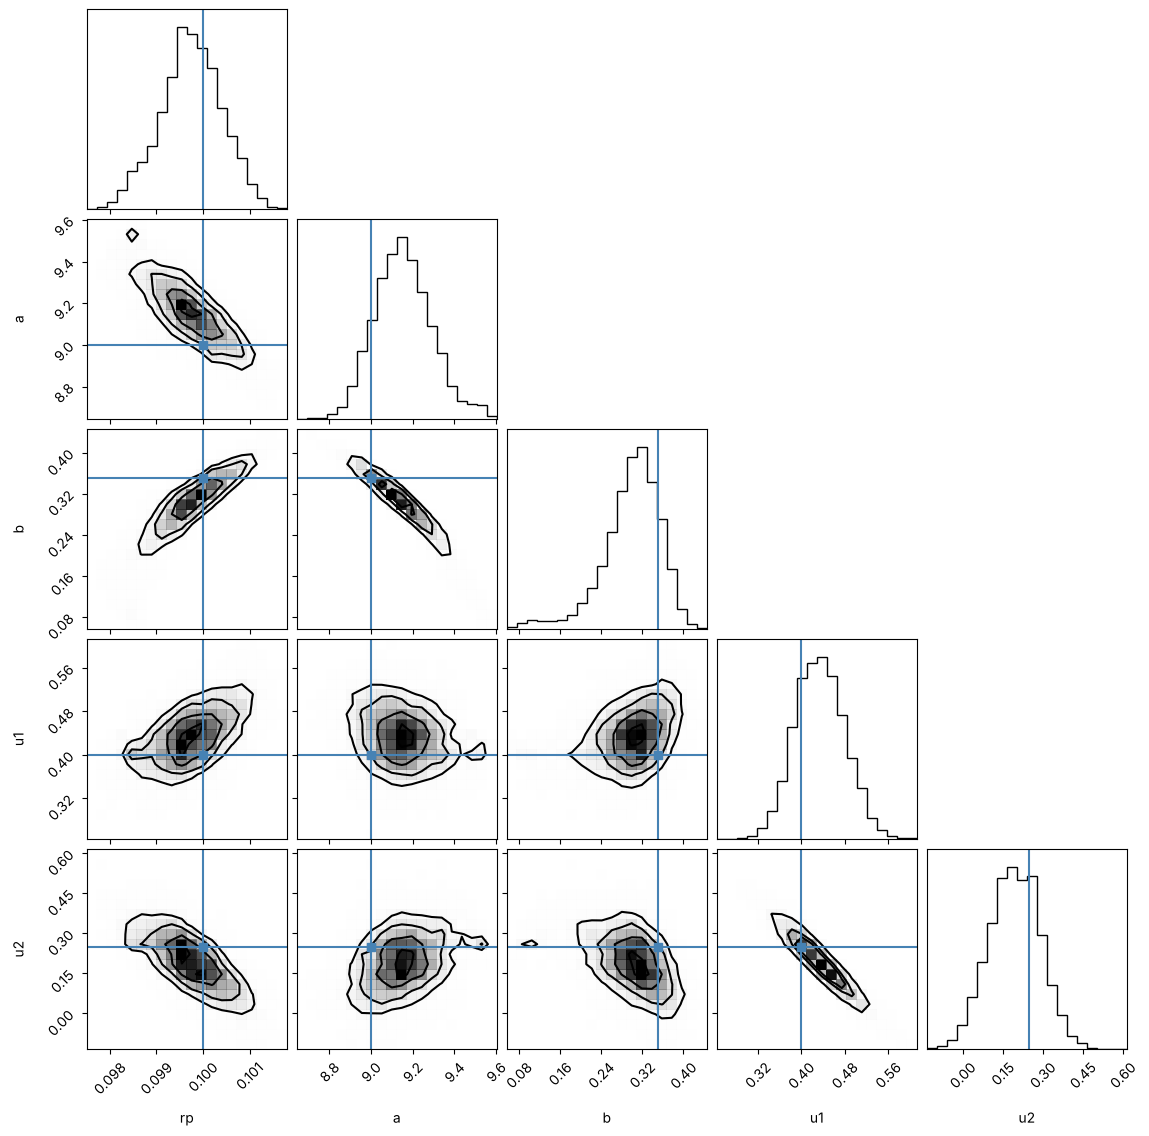

In [6]:
sel = [2, 3, 4, 5, 6]
corner.corner(chain[:, sel], labels=[names[i] for i in sel], truths=th_true[sel], plot_datapoints=False);

The radius ratio, `a` and `b` are correlated (a grazing, shorter chord can mimic a smaller orbit), and so
are the two limb-darkening coefficients. Notebook 06 shows how to integrate the limb darkening out of
the fit altogether, which makes such fits much faster.

## 5. Check the fit

reduced chi^2: 0.988


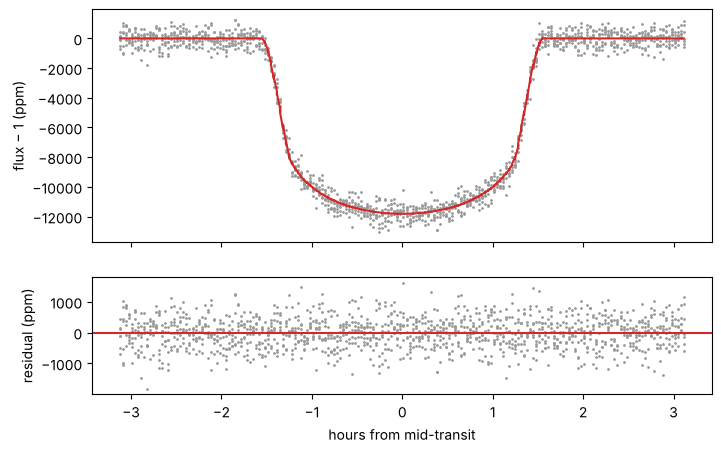

In [7]:
set_params(np.median(chain, axis=0))
f = model.light_curve(params)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True, gridspec_kw=dict(height_ratios=(2, 1)))
o = np.argsort(fold)
a1.plot(24 * fold, 1e6 * (y - 1), ".", ms=2, color="0.6"); a1.plot(24 * fold[o], 1e6 * (f[o] - 1), "C3")
a2.plot(24 * fold, 1e6 * (y - f), ".", ms=2, color="0.6"); a2.axhline(0, color="C3")
a1.set_ylabel("flux − 1 (ppm)"); a2.set(xlabel="hours from mid-transit", ylabel="residual (ppm)")
print(f"reduced chi^2: {np.sum((y - f)**2) / sigma**2 / (t.size - 7):.3f}")

## What you learned

- A likelihood is a few lines around `model.light_curve(params)`; keep one `TransitModel` and update `params`.
- Maximum likelihood with scipy, then emcee for the uncertainties; check acceptance and autocorrelation times.
- Sample `b` rather than `inc`, and restrict the limb darkening to physical profiles.

**Next:** [04 · Observing realities](04_observing_realities.ipynb)